# Data Import & **Cleaning**

---





In [ ]:
import pandas as pd

# โหลดไฟล์
df = pd.read_excel("รายได้เฉลี่ยต่อเดือนของครัวเรือน.xlsx")

df.head()

,Year,Region,Soc_eco_class,Source_income,value,unit,source
0,2566,ภาคเหนือ,ผู้ถือครองทำการเกษตร/เพาะเลี้ยง : ปลูกพืช/เลี้...,รายได้ไม่ประจำ (ที่เป็นตัวเงิน),204,บาท,สำนักงานสถิติแห่งชาติ
1,2566,ภาคเหนือ,ผู้ถือครองทำการเกษตร/เพาะเลี้ยง : ปลูกพืช/เลี้...,รายได้ประจำ,22502,บาท,สำนักงานสถิติแห่งชาติ
2,2566,ภาคเหนือ,ผู้ถือครองทำการเกษตร/เพาะเลี้ยง : ปลูกพืช/เลี้...,รายได้ไม่ประจำ (ที่เป็นตัวเงิน),201,บาท,สำนักงานสถิติแห่งชาติ
3,2566,ภาคเหนือ,"ผู้ถือครองทำการเกษตร/เพาะเลี้ยง : ประมง,ป่าไม้...",รายได้ประจำ,15007,บาท,สำนักงานสถิติแห่งชาติ
4,2566,ภาคเหนือ,"ผู้ถือครองทำการเกษตร/เพาะเลี้ยง : ประมง,ป่าไม้...",รายได้ไม่ประจำ (ที่เป็นตัวเงิน),133,บาท,สำนักงานสถิติแห่งชาติ


*ตรวจสอบโครงสร้างตัวแปร*

In [ ]:
df.info()
df.describe()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Year           918 non-null    int64 
 1   Region         918 non-null    object
 2   Soc_eco_class  918 non-null    object
 3   Source_income  918 non-null    object
 4   value          918 non-null    int64 
 5   unit           918 non-null    object
 6   source         918 non-null    object
dtypes: int64(2), object(5)
memory usage: 50.3+ KB


Index(['Year', 'Region', 'Soc_eco_class', 'Source_income', 'value', 'unit',
       'source'],
      dtype='object')

Missing Values

In [ ]:
df.isnull().sum()

,0
Year,0
Region,0
Soc_eco_class,0
Source_income,0
value,0
unit,0
source,0


In [ ]:
df = df.fillna(0)

In [ ]:
df = df.drop_duplicates()

In [ ]:
df["Year"] = df["Year"] + 543

In [ ]:
df["Region"].unique()

array(['ภาคเหนือ', 'ภาคตะวันออกเฉียงเหนือ', 'ภาคใต้', 'ทั่วราชอาณาจักร',
       'กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ', 'ภาคกลาง'],
      dtype=object)

In [ ]:
df["Region"] = df["Region"].astype(str).str.strip()

# Data **Transformation**

คำนวณ “รายได้รวม” ต่อปี ต่อภูมิภาค

In [ ]:
total_income = df.groupby(
    ["Year", "Region"]
)["value"].sum().reset_index()

total_income = total_income.rename(columns={"value": "Total_income"})

total_income.head()

,Year,Region,Total_income
0,3097,กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ,354557
1,3097,ทั่วราชอาณาจักร,237230
2,3097,ภาคกลาง,223646
3,3097,ภาคตะวันออกเฉียงเหนือ,198499
4,3097,ภาคเหนือ,186222




---


รวมกลับเข้า dataframe หลัก

In [ ]:
df = df.merge(total_income, on=["Year", "Region"])

# **Feature Engineering**

**คำนวณสัดส่วนรายได้แต่ละประเภท**

In [ ]:
df["Income_share"] = df["value"] / df["Total_income"]

**คำนวณอัตราการเติบโตของรายได้รวม**

In [ ]:
total_income["Growth_rate (%)"] = (
    total_income.groupby("Region")["Total_income"]
    .pct_change() * 100
)

total_income.head()

,Year,Region,Total_income,Growth_rate (%)
0,3097,กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ,354557,NaN
1,3097,ทั่วราชอาณาจักร,237230,NaN
2,3097,ภาคกลาง,223646,NaN
3,3097,ภาคตะวันออกเฉียงเหนือ,198499,NaN
4,3097,ภาคเหนือ,186222,NaN


**วิเคราะห์การเปลี่ยนแปลงโครงสร้างรายได้**

In [ ]:
structure = df.groupby(
    ["Year", "Region", "Source_income"]
)["Income_share"].mean().reset_index()

structure.head()

,Year,Region,Source_income,Income_share
0,3097,กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ,รายได้ประจำ,0.099706
1,3097,กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ,รายได้ไม่ประจำ (ที่เป็นตัวเงิน),0.000294
2,3097,ทั่วราชอาณาจักร,รายได้ประจำ,0.089544
3,3097,ทั่วราชอาณาจักร,รายได้ไม่ประจำ (ที่เป็นตัวเงิน),0.001365
4,3097,ภาคกลาง,รายได้ประจำ,0.089729


# Aggregation and Income Trend Preparation

In [ ]:
total_income = df.groupby(
    ["Year", "Region"]
)["value"].sum().reset_index()

total_income = total_income.rename(columns={"value": "Total_income"})

region_map = {
    "กรุงเทพมหานคร และปริมณฑล": "Bangkok Metropolitan",
    "ทั่วราชอาณาจักร": "Whole Kingdom",
    "ภาคกลาง": "Central",
    "ภาคตะวันออกเฉียงเหนือ": "Northeast",
    "ภาคเหนือ": "North",
    "ภาคใต้": "South"
}

total_income["Region_EN"] = total_income["Region"].map(region_map)

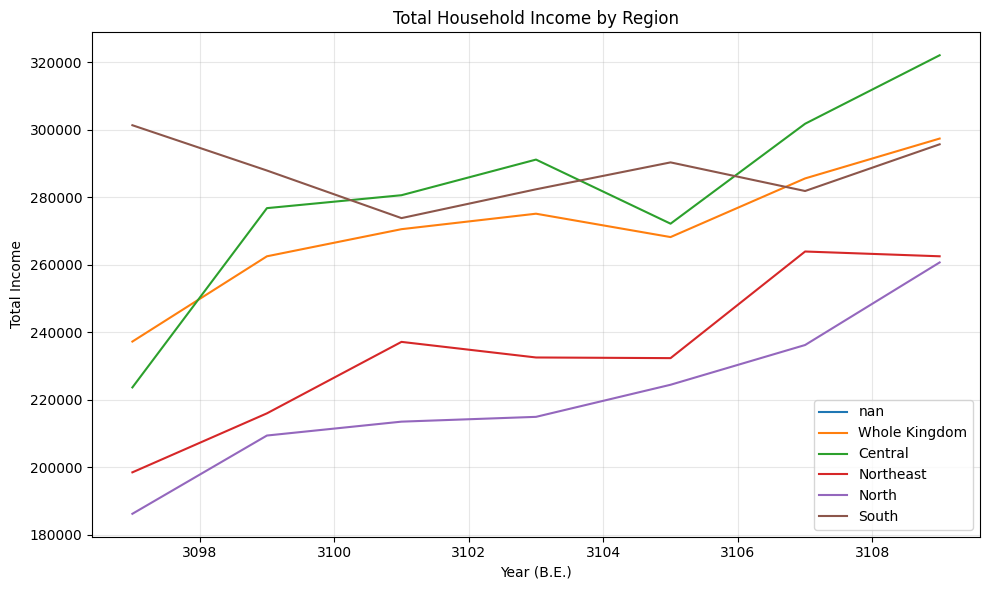

In [ ]:
plt.figure(figsize=(10,6))

for region in total_income["Region_EN"].unique():
    temp = total_income[total_income["Region_EN"] == region]
    plt.plot(temp["Year"], temp["Total_income"], label=region)

plt.xlabel("Year (B.E.)")
plt.ylabel("Total Income")
plt.title("Total Household Income by Region")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Exploratory Data Analysis (EDA)

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# อ่านข้อมูล
df = pd.read_excel("รายได้เฉลี่ยต่อเดือนของครัวเรือน.xlsx")

# ตรวจสอบข้อมูล
df.head()

# รวมรายได้ตามปีและภูมิภาค
income_region = df.groupby(["Year","Region"])["value"].sum().reset_index()



---


**วิเคราะห์การกระจายของรายได้**

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "DejaVu Sans"

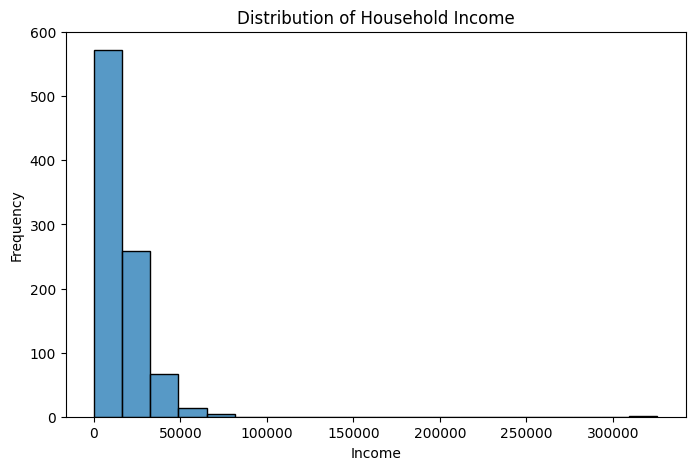

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df["value"], bins=20)

plt.title("Distribution of Household Income")
plt.xlabel("Income")
plt.ylabel("Frequency")

plt.show()



---


**เปรียบเทียบรายได้แต่ละภูมิภาค**

In [ ]:
total_income = df.groupby(
    ["Year", "Region"]
)["value"].sum().reset_index()

total_income = total_income.rename(columns={"value": "Total_income"})

region_map = {
    "กรุงเทพมหานคร และปริมณฑล": "Bangkok Metropolitan",
    "ทั่วราชอาณาจักร": "Whole Kingdom",
    "ภาคกลาง": "Central",
    "ภาคตะวันออกเฉียงเหนือ": "Northeast",
    "ภาคเหนือ": "North",
    "ภาคใต้": "South"
}

total_income["Region_EN"] = total_income["Region"].map(region_map)

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3640 (\N{THAI CHARACTER SARA U}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)

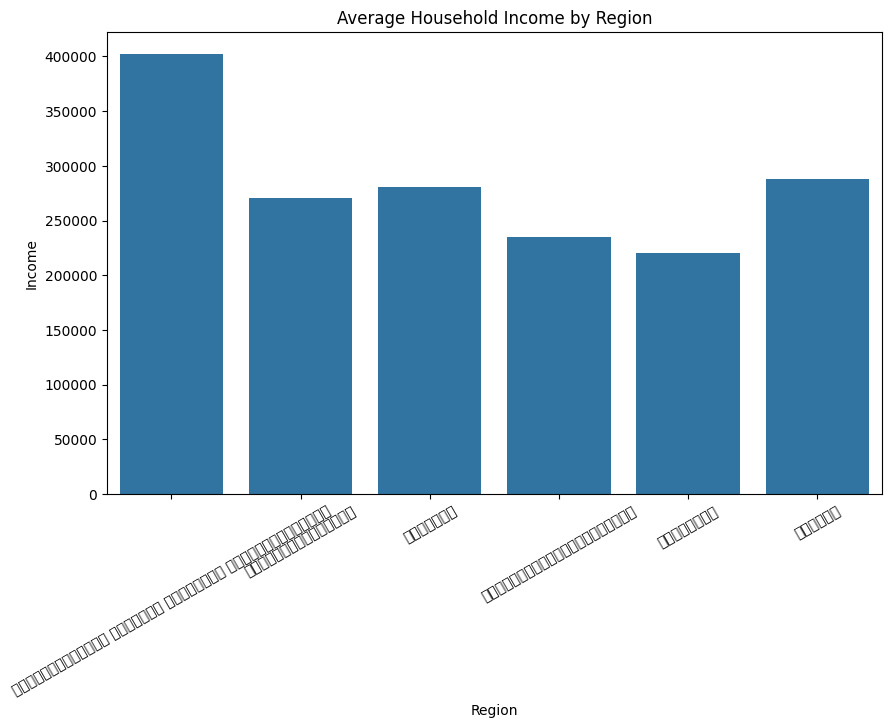

In [ ]:
region_avg = income_region.groupby("Region")["value"].mean().reset_index()

plt.figure(figsize=(10,6))

sns.barplot(data=region_avg,
            x="Region",
            y="value")

plt.title("Average Household Income by Region")
plt.xlabel("Region")
plt.ylabel("Income")

plt.xticks(rotation=30)

plt.show()



---


**แนวโน้มรายได้ตามช่วงเวลา**


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3585 (\N{THAI CHARACTER KO KAI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3640 (\N{THAI CHARACTER SARA U}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3591 (\N{THAI CHARACTER NGO NGU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)

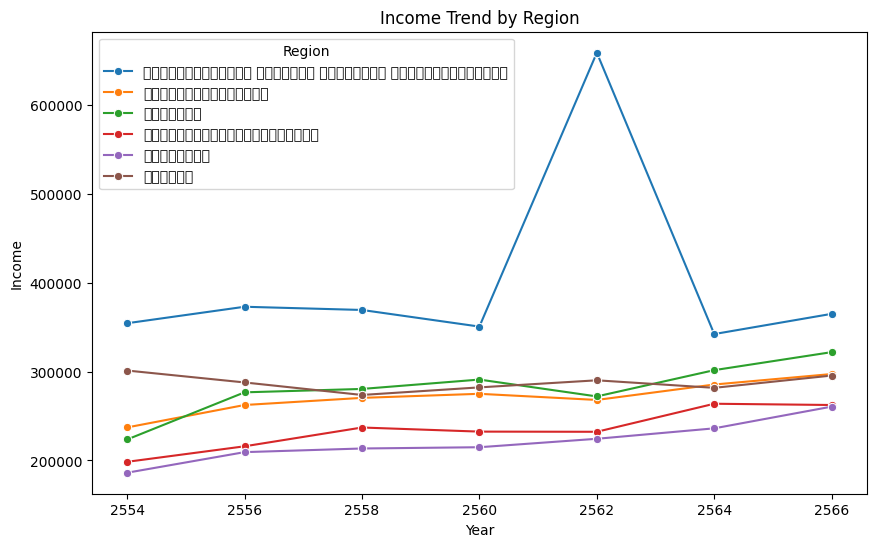

In [ ]:
plt.figure(figsize=(10,6))

sns.lineplot(data=income_region,
             x="Year",
             y="value",
             hue="Region",
             marker="o")

plt.title("Income Trend by Region")
plt.xlabel("Year")
plt.ylabel("Income")

plt.show()



---


**ตรวจสอบความเปลี่ยนแปลงของรายได้ในแต่ละปี**

In [ ]:
pivot_income = income_region.pivot(index="Year", columns="Region", values="value")

pivot_income

Region,กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ,ทั่วราชอาณาจักร,ภาคกลาง,ภาคตะวันออกเฉียงเหนือ,ภาคเหนือ,ภาคใต้
Year,,,,,,
2554,354557,237230,223646,198499,186222,301293
2556,373112,262478,276739,215970,209400,287879
2558,369501,270510,280566,237133,213511,273787
2560,350776,275090,291118,232514,214930,282318
2562,659172,268170,272136,232321,224435,290288
2564,342371,285540,301730,263895,236206,281814
2566,365133,297344,322013,262481,260660,295643




---


# **Time-Based Analysis**

**คำนวณ Growth Rate**

In [ ]:
pivot_income_growth = pivot_income.pct_change()*100

pivot_income_growth

Region,กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ,ทั่วราชอาณาจักร,ภาคกลาง,ภาคตะวันออกเฉียงเหนือ,ภาคเหนือ,ภาคใต้
Year,,,,,,
2554,NaN,NaN,NaN,NaN,NaN,NaN
2556,5.233291,10.642836,23.739749,8.801556,12.446435,-4.452145
2558,-0.967806,3.060066,1.382891,9.799046,1.963228,-4.895112
2560,-5.067645,1.693098,3.760969,-1.947852,0.664603,3.115926
2562,87.918216,-2.515540,-6.520380,-0.083006,4.422370,2.823058
2564,-48.060446,6.477235,10.874710,13.590678,5.244726,-2.919170
2566,6.648343,4.133922,6.722235,-0.535819,10.352828,4.907137




---

**วิเคราะห์แนวโน้มรายได้**





<Figure size 1000x600 with 0 Axes>

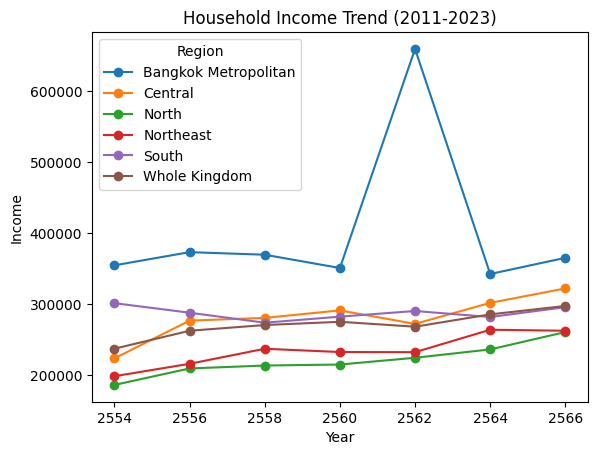

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reload the original dataframe to ensure 'Region' column is intact
df = pd.read_excel("รายได้เฉลี่ยต่อเดือนของครัวเรือน.xlsx")

region_map = {
    "ทั่วราชอาณาจักร": "Whole Kingdom",
    "กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ": "Bangkok Metropolitan",
    "ภาคกลาง": "Central",
    "ภาคตะวันออกเฉียงเหนือ": "Northeast",
    "ภาคเหนือ": "North",
    "ภาคใต้": "South"
}

df["Region"] = df["Region"].map(region_map)

income_region = df.groupby(["Year","Region"])["value"].sum().reset_index()

pivot_income = income_region.pivot(index="Year", columns="Region", values="value")

plt.figure(figsize=(10,6))

pivot_income.plot(marker="o")

plt.title("Household Income Trend (2011-2023)")
plt.xlabel("Year")
plt.ylabel("Income")

plt.show()

**วิเคราะห์ภูมิภาคที่โตเร็วสุด**

In [ ]:
growth_mean = pivot_income_growth.mean().sort_values(ascending=False)

growth_mean

,0
Region,
กรุงเทพมหานคร นนทบุรี ปทุมธานี และสมุทรปราการ,7.617326
ภาคกลาง,6.660029
ภาคเหนือ,5.849032
ภาคตะวันออกเฉียงเหนือ,4.937434
ทั่วราชอาณาจักร,3.915269
ภาคใต้,-0.236718


### วัตถุประสงค์ที่ 1: การสำรวจสถิติเชิงพรรณนาและแนวโน้มรายได้ตามภูมิภาค (Income Trend EDA)

In [ ]:

regional_statistics = df.groupby(['Year', 'Region'])['value'].agg(['mean', 'median', 'max', 'min']).reset_index()


regional_statistics.columns = ['Year', 'Region', 'Mean_Income', 'Median_Income', 'Max_Income', 'Min_Income']


regional_statistics.head()

,Year,Region,Mean_Income,Median_Income,Max_Income,Min_Income
0,2554,Bangkok Metropolitan,17727.850000,7235.5,73246,0
1,2554,Central,10165.727273,5699.5,39052,59
2,2554,North,8464.636364,4091.0,40353,105
3,2554,Northeast,9022.681818,4797.5,43772,123
4,2554,South,13695.136364,5944.0,53670,121


# Gini Index

In [ ]:
import numpy as np
import pandas as pd

def gini(array):
    array = np.array(array)
    if np.amin(array) < 0:
        array -= np.amin(array)
    array = np.sort(array)
    n = len(array)
    index = np.arange(1, n + 1)
    g = (
        np.sum((2 * index - n - 1) * array)
    ) / (n * np.sum(array))
    return g

gini_results = []
for (year, region), group in df.groupby(["Year","Region"]):
    gini_value = gini(group["value"])
    gini_results.append({
        "Year": year,
        "Region": region,
        "gini_index": gini_value
    })

gini_df = pd.DataFrame(gini_results)
print(gini_df.head())




   Year                Region  gini_index
0  2554  Bangkok Metropolitan    0.631118
1  2554               Central    0.582122
2  2554                 North    0.602270
3  2554             Northeast    0.599166
4  2554                 South    0.617875


## Export Dataset

In [ ]:
gini_df.to_excel("gini_index_dataset.xlsx", index=False)